# TCX3901 Industrial Practice - EDA
## SmartCommerce Data Exploration

**Environment:** Google Colab (recommended) or local Jupyter Lab

---

### 🎯 Objectives

This is for you to:

1. Load and understand the **Olist e-commerce dataset** schema
2. **Merge multiple tables** using relational keys (order_id, customer_id, product_id)
3. Compute foundational **business KPIs** (E.g. Revenue, AOV, Repeat Rate, On-Time Delivery)
4. Create basic **visualizations** to understand data distributions
5. Document the data assets available for downstream analytics

---

### 📊 About The Dataset

**Olist** is a Brazilian e-commerce platform. The dataset contains ~100K orders from 2016-2018 across 9 interconnected tables:

| Table | Description | Key Columns |
|-------|-------------|-------------|
| `orders` | Order metadata & timestamps | order_id, customer_id, status, timestamps |
| `order_items` | Line items per order | order_id, product_id, price, freight |
| `customers` | Customer location | customer_id, city, state |
| `products` | Product catalog | product_id, category, dimensions |
| `sellers` | Seller location | seller_id, city, state |
| `payments` | Payment details | order_id, payment_type, value |
| `reviews` | Customer feedback | order_id, score, comment |
| `geolocation` | Zip code coordinates | zip_code, lat, lng |
| `category_translation` | Portuguese → English | category names |

> 💡 **SmartCommerce** will be our fictional brand name for this e-commerce case study throughout the course.


---

## 1. Environment Setup & Data Loading

In [48]:
# Install dependencies (uncomment if running in Colab)
# !pip install -q pandas numpy matplotlib seaborn plotly

import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None) # Show all columns
pd.set_option("display.max_colwidth", None) # Allow full text width for long column strings
pd.set_option("display.width", None) # Do not wrap columns to a new line
pd.set_option("display.float_format", "{:.2f}".format)

print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")

pandas: 3.0.3
numpy: 2.4.6


In [5]:
# === DATASET PATH CONFIGURATION ===
# Option: Local path (adjust to your setup)
DATA_DIR = "./Dataset" # Relative path - adjust as needed

# Verify data directory exists
if os.path.exists(DATA_DIR):
    print(f"✅ Data directory found: {DATA_DIR}")
    print(f"Files: {os.listdir(DATA_DIR)}")
else:
    print(f"❌ Data directory not found: {DATA_DIR}")
    print("Please update DATA_DIR to point to your dataset folder")

✅ Data directory found: ./Dataset
Files: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [6]:
# Load all dataset tables
def load_data(data_dir):
    """Load all data CSV files into a dictionary of DataFrames."""

    tables = {
        "orders": "olist_orders_dataset.csv",
        "order_items": "olist_order_items_dataset.csv",
        "customers": "olist_customers_dataset.csv",
        "products": "olist_products_dataset.csv",
        "sellers": "olist_sellers_dataset.csv",
        "payments": "olist_order_payments_dataset.csv",
        "reviews": "olist_order_reviews_dataset.csv",
        "geolocation": "olist_geolocation_dataset.csv",
        "category_translation": "product_category_name_translation.csv"
    }

    # Date columns to parse
    date_cols = {
        "orders": ["order_purchase_timestamp", "order_approved_at",
                   "order_delivered_carrier_date", "order_delivered_customer_date",
                   "order_estimated_delivery_date"],
        "order_items": ["shipping_limit_date"],
        "reviews": ["review_creation_date", "review_answer_timestamp"]
    }

    data = {}
    for name, filename in tables.items():
        filepath = os.path.join(data_dir, filename)
        parse_dates = date_cols.get(name, None)
        data[name] = pd.read_csv(filepath, parse_dates=parse_dates)
        print(f"Loaded {name}: {data[name].shape[0]:,} rows × {data[name].shape[1]} cols")

    return data

# Load data
data = load_data(DATA_DIR)

Loaded orders: 99,441 rows × 8 cols
Loaded order_items: 112,650 rows × 7 cols
Loaded customers: 99,441 rows × 5 cols
Loaded products: 32,951 rows × 9 cols
Loaded sellers: 3,095 rows × 4 cols
Loaded payments: 103,886 rows × 5 cols
Loaded reviews: 99,224 rows × 7 cols
Loaded geolocation: 1,000,163 rows × 5 cols
Loaded category_translation: 71 rows × 2 cols


---

## 2. Schema Exploration

Understanding each table's structure and relationships.


In [7]:
# Quick schema overview
def schema_summary(data_dict):
    """Generate a summary of all tables."""
    summary = []
    for name, df in data_dict.items():
        summary.append({
            "Table": name,
            "Rows": f"{df.shape[0]:,}",
            "Columns": df.shape[1],
            "Memory (MB)": f"{df.memory_usage(deep=True).sum() / 1e6:.2f}",
            "Columns List": ", ".join(df.columns) # Concatenates every column name for display
        })
    return pd.DataFrame(summary)

schema_summary(data)

,Table,Rows,Columns,Memory (MB),Columns List
0,orders,"99,441",8,13.62,"order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date"
1,order_items,"112,650",7,17.12,"order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value"
2,customers,"99,441",5,11.57,"customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state"
3,products,"32,951",9,3.91,"product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm"
4,sellers,"3,095",4,0.24,"seller_id, seller_zip_code_prefix, seller_city, seller_state"
5,payments,"103,886",5,8.50,"order_id, payment_sequential, payment_type, payment_installments, payment_value"
6,reviews,"99,224",7,14.94,"review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp"
7,geolocation,"1,000,163",5,52.56,"geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state"
8,category_translation,71,2,0.00,"product_category_name, product_category_name_english"


### 2.1 Orders Table

In [8]:
# Orders table
orders = data["orders"]
print("=" * 50)
print("ORDERS TABLE")
print("=" * 50)
print(f"Shape: {orders.shape}")
print(f"\nColumn types:\n{orders.dtypes}")
print(f"\nOrder status distribution:\n{orders["order_status"].value_counts()}")
orders.head(5)

ORDERS TABLE
Shape: (99441, 8)

Column types:
order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


### 2.2 Order Items Table (Line-Level Details)

In [9]:
# Order Items - contains price and freight
order_items = data["order_items"]
print("=" * 50)
print("ORDER ITEMS TABLE")
print("=" * 50)
print(f"Shape: {order_items.shape}")
print(f"\nPrice statistics:")
print(order_items[["price", "freight_value"]].describe())
order_items.head(5)

ORDER ITEMS TABLE
Shape: (112650, 7)

Price statistics:
          price  freight_value
count 112650.00      112650.00
mean     120.65          19.99
std      183.63          15.81
min        0.85           0.00
25%       39.90          13.08
50%       74.99          16.26
75%      134.90          21.15
max     6735.00         409.68


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### 2.3 Customers Table

In [10]:
# Customers
customers = data["customers"]
print("=" * 50)
print("CUSTOMERS TABLE")
print("=" * 50)
print(f"Shape: {customers.shape}")
print(f"Unique customers: {customers["customer_unique_id"].nunique():,}")
print(f"\nTop 10 states:")
print(customers["customer_state"].value_counts().head(10))
customers.head(5)

CUSTOMERS TABLE
Shape: (99441, 5)
Unique customers: 96,096

Top 10 states:
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### 2.4 Products Table

In [11]:
# Products with category translation
products = data["products"].merge(
    data["category_translation"],
    on="product_category_name",
    how="left"
)
products["product_category_name_english"] = products["product_category_name_english"].fillna("Unknown")

print("=" * 50)
print("PRODUCTS TABLE (With English Categories)")
print("=" * 50)
print(f"Shape: {products.shape}")
print(f"\nTop 10 categories:")
print(products["product_category_name_english"].value_counts().head(10))
products.head(5)

PRODUCTS TABLE (With English Categories)
Shape: (32951, 10)

Top 10 categories:
product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,1000.00,30.00,18.00,20.00,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00,housewares


### 2.5 Sellers Table

In [12]:
# Sellers
sellers = data["sellers"]
print("=" * 50)
print("SELLERS TABLE")
print("=" * 50)
print(f"Shape: {sellers.shape}")
print(f"Unique sellers: {sellers["seller_id"].nunique():,}")
print(f"\nTop 10 states:")
print(sellers["seller_state"].value_counts().head(10))
sellers.head(5)

SELLERS TABLE
Shape: (3095, 4)
Unique sellers: 3,095

Top 10 states:
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


### 2.6 Payments Table (Line-Level Details)

In [13]:
# Payments
payments = data["payments"]
print("=" * 50)
print("PAYMENTS TABLE")
print("=" * 50)
print(f"Shape: {payments.shape}")
print(f"Unique orders: {payments["order_id"].nunique():,}")
print(f"Maximum number of payment installments: {payments["payment_installments"].max():,}")
print(f"\nColumn types:\n{payments.dtypes}")
print(f"\nTop 5 payment types:")
print(payments["payment_type"].value_counts().head(5))
print(f"\nTop 10 number of payment installments:")
print(payments["payment_installments"].value_counts().head(10))
payments.head(5)

PAYMENTS TABLE
Shape: (103886, 5)
Unique orders: 99,440
Maximum number of payment installments: 24

Column types:
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

Top 5 payment types:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Top 10 number of payment installments:
payment_installments
1     52546
2     12413
3     10461
4      7098
10     5328
5      5239
8      4268
6      3920
7      1626
9       644
Name: count, dtype: int64


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### 2.7 Reviews Table (Customer Feedback)

In [11]:
# Reviews
reviews = data["reviews"]
print("=" * 50)
print("REVIEWS TABLE")
print("=" * 50)
print(f"Shape: {reviews.shape}")
print(f"\nReview score distribution:")
print(reviews["review_score"].value_counts().sort_index())
print(f"\nReviews with comments: {reviews["review_comment_message"].notna().sum():,} ({reviews["review_comment_message"].notna().mean():.1%})")
reviews.head(5)

REVIEWS TABLE
Shape: (99224, 7)

Review score distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Reviews with comments: 40,977 (41.3%)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa,2018-03-01,2018-03-02 10:26:53


---

## 3. Merging Tables (Building The Analysis Dataset)

The dataset tables are **relational** — they connect via shared keys. Let's build a consolidated dataset for analysis.

In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "./Olist"

orders = pd.read_csv(f"{DATA_PATH}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{DATA_PATH}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{DATA_PATH}/olist_products_dataset.csv")
customers = pd.read_csv(f"{DATA_PATH}/olist_customers_dataset.csv")
sellers = pd.read_csv(f"{DATA_PATH}/olist_sellers_dataset.csv")
payments = pd.read_csv(f"{DATA_PATH}/olist_order_payments_dataset.csv")

category_translation = pd.read_csv(
    f"{DATA_PATH}/product_category_name_translation.csv"
)

In [14]:
order_items_agg = (
    order_items
    .groupby("order_id")
    .agg(
        number_of_items=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        average_item_price=("price", "mean"),
        average_item_freight=("freight_value", "mean"),
        number_of_sellers=("seller_id", "nunique"),
        number_of_products=("product_id", "nunique")
    )
    .reset_index()
)

order_items_agg.head()

,order_id,number_of_items,total_price,total_freight,average_item_price,average_item_freight,number_of_sellers,number_of_products
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,58.90,13.29,1,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,239.90,19.93,1,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,199.00,17.87,1,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,12.99,12.79,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,199.90,18.14,1,1


In [15]:
order_items_agg["order_value"] = (
    order_items_agg["total_price"] +
    order_items_agg["total_freight"]
)

In [16]:
items_products = order_items.merge(
    products,
    on="product_id",
    how="left"
)

In [17]:
product_agg = (
    items_products
    .groupby("order_id")
    .agg(
        average_product_weight_g=("product_weight_g", "mean"),
        average_product_length_cm=("product_length_cm", "mean"),
        average_product_height_cm=("product_height_cm", "mean"),
        average_product_width_cm=("product_width_cm", "mean"),
        number_of_categories=("product_category_name", "nunique")
    )
    .reset_index()
)

In [18]:
customer_data = customers[
    [
        "customer_id",
        "customer_city",
        "customer_state"
    ]
].copy()

In [19]:
orders_customer = orders.merge(
    customer_data,
    on="customer_id",
    how="left"
)

In [20]:
items_sellers = order_items.merge(
    sellers[
        [
            "seller_id",
            "seller_city",
            "seller_state"
        ]
    ],
    on="seller_id",
    how="left"
)

In [21]:
seller_agg = (
    items_sellers
    .groupby("order_id")
    .agg(
        number_of_sellers=("seller_id", "nunique"),
        number_of_seller_states=("seller_state", "nunique")
    )
    .reset_index()
)

In [22]:
primary_seller_state = (
    items_sellers
    .groupby("order_id")["seller_state"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    .reset_index(name="primary_seller_state")
)

In [23]:
payment_agg = (
    payments
    .groupby("order_id")
    .agg(
        number_of_payment_records=("payment_sequential", "count"),
        payment_installments=("payment_installments", "max")
    )
    .reset_index()
)

In [24]:
payment_type = (
    payments
    .groupby("order_id")["payment_type"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    .reset_index(name="payment_type")
)

In [25]:
df = orders_customer.copy()

df = df.merge(
    order_items_agg,
    on="order_id",
    how="left"
)

df = df.merge(
    product_agg,
    on="order_id",
    how="left"
)

df = df.merge(
    seller_agg,
    on="order_id",
    how="left"
)

df = df.merge(
    primary_seller_state,
    on="order_id",
    how="left"
)

df = df.merge(
    payment_agg,
    on="order_id",
    how="left"
)

df = df.merge(
    payment_type,
    on="order_id",
    how="left"
)

In [26]:
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"]
)

In [27]:
df["purchase_year"] = df["order_purchase_timestamp"].dt.year
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_day"] = df["order_purchase_timestamp"].dt.day
df["purchase_dayofweek"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour

In [28]:
df = df.drop(columns=["order_purchase_timestamp"])

In [29]:
leakage_columns = [
    "price",
    "freight_value",
    "total_price",
    "total_freight",
    "order_value",
    "payment_value"
]

In [30]:
df_model = df.drop(
    columns=[
        "total_price",
        "total_freight"
    ],
    errors="ignore"
)

In [31]:
future_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

In [32]:
df_model = df_model.drop(
    columns=future_columns,
    errors="ignore"
)

In [33]:
print("Number of rows:", len(df_model))
print("Number of unique orders:", df_model["order_id"].nunique())

Number of rows: 99441
Number of unique orders: 99441


In [34]:
duplicate_orders = df_model["order_id"].duplicated().sum()

print("Duplicate order IDs:", duplicate_orders)

assert df_model["order_id"].is_unique

Duplicate order IDs: 0


In [35]:
integer_columns = [
    "number_of_items",
    "number_of_sellers",
    "number_of_products",
    "number_of_categories",
    "number_of_payment_records"
]

for col in integer_columns:
    if col in df.columns:
        df[col] = df[col].astype("Int64")

In [36]:
print(df_model.shape)
print(df_model.head())
print(df_model.info())

(99441, 27)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status            customer_city customer_state  number_of_items  \
0    delivered                sao paulo             SP             1.00   
1    delivered                barreiras             BA             1.00   
2    delivered               vianopolis             GO             1.00   
3    delivered  sao goncalo do amarante             RN             1.00   
4    delivered              santo andre             SP             1.00   

   average_item_price  average_item_freight  number_of_sellers_x  \
0               29.99         

In [37]:
print(df_model.isnull().sum().sort_values(ascending=False).head(20))

average_product_height_cm    791
average_product_length_cm    791
average_product_weight_g     791
average_product_width_cm     791
order_value                  775
average_item_freight         775
number_of_categories         775
number_of_products           775
number_of_sellers_x          775
number_of_items              775
average_item_price           775
number_of_seller_states      775
number_of_sellers_y          775
primary_seller_state         775
number_of_payment_records      1
payment_type                   1
payment_installments           1
order_id                       0
order_status                   0
customer_state                 0
dtype: int64


In [38]:
df_model.to_csv(
    "olist_order_level.csv",
    index=False
)

In [39]:
# ============================================================
# OLIST ORDER VALUE PROJECT
# DATA PREPROCESSING + EDA
# REGRESSION AND CLASSIFICATION
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [40]:
# ============================================================
# 2. LOAD DATA
# ============================================================

# This should be the order-level dataset produced after
# joining and aggregating the Olist tables.

df = pd.read_csv("olist_order_level.csv")

print("=" * 70)
print("INITIAL DATASET")
print("=" * 70)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

INITIAL DATASET
Rows: 99441
Columns: 27

Columns:
['order_id', 'customer_id', 'order_status', 'customer_city', 'customer_state', 'number_of_items', 'average_item_price', 'average_item_freight', 'number_of_sellers_x', 'number_of_products', 'order_value', 'average_product_weight_g', 'average_product_length_cm', 'average_product_height_cm', 'average_product_width_cm', 'number_of_categories', 'number_of_sellers_y', 'number_of_seller_states', 'primary_seller_state', 'number_of_payment_records', 'payment_installments', 'payment_type', 'purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_hour']

First 5 rows:
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d8

In [41]:
# ============================================================
# 3. BASIC DATA QUALITY CHECK
# ============================================================

print("\n" + "=" * 70)
print("DATA QUALITY CHECK")
print("=" * 70)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage":
        df.isnull().mean() * 100
})

print(
    missing
    .sort_values("missing_percentage", ascending=False)
)

print("\nDuplicate rows:")
print(df.duplicated().sum())


DATA QUALITY CHECK

Data types:
order_id                         str
customer_id                      str
order_status                     str
customer_city                    str
customer_state                   str
number_of_items              float64
average_item_price           float64
average_item_freight         float64
number_of_sellers_x          float64
number_of_products           float64
order_value                  float64
average_product_weight_g     float64
average_product_length_cm    float64
average_product_height_cm    float64
average_product_width_cm     float64
number_of_categories         float64
number_of_sellers_y          float64
number_of_seller_states      float64
primary_seller_state             str
number_of_payment_records    float64
payment_installments         float64
payment_type                     str
purchase_year                  int64
purchase_month                 int64
purchase_day                   int64
purchase_dayofweek             int64
purch

In [42]:
# ============================================================
# 4. ENSURE ONE ROW = ONE ORDER
# ============================================================

print("\n" + "=" * 70)
print("ORDER-LEVEL GRANULARITY")
print("=" * 70)

if "order_id" in df.columns:

    print("Total rows:",
          len(df))

    print("Unique order IDs:",
          df["order_id"].nunique())

    if len(df) == df["order_id"].nunique():
        print("✓ Dataset is at order level.")
    else:
        print("⚠ Multiple rows per order detected.")


ORDER-LEVEL GRANULARITY
Total rows: 99441
Unique order IDs: 99441
✓ Dataset is at order level.


In [43]:
# ============================================================
# 5. REMOVE DUPLICATE ORDERS
# ============================================================

if "order_id" in df.columns:

    duplicate_orders = df["order_id"].duplicated().sum()

    if duplicate_orders > 0:

        print(
            f"\nRemoving {duplicate_orders} "
            "duplicate order records."
        )

        df = df.drop_duplicates(
            subset="order_id"
        )


In [44]:
# ============================================================
# 6. CREATE ORDER VALUE TARGET
# ============================================================

# Order Value =
# total item price + total freight value

if "order_value" not in df.columns:

    if (
        "total_price" in df.columns
        and
        "total_freight" in df.columns
    ):

        df["order_value"] = (
            df["total_price"]
            +
            df["total_freight"]
        )

    else:

        raise ValueError(
            "Cannot create order_value. "
            "Expected total_price and total_freight."
        )

In [45]:
# ============================================================
# 7. TARGET QUALITY CHECK
# ============================================================

print("\n" + "=" * 70)
print("ORDER VALUE TARGET")
print("=" * 70)

print(
    df["order_value"].describe()
)

print(
    "\nMissing order values:",
    df["order_value"].isnull().sum()
)

print(
    "Zero/negative order values:",
    (df["order_value"] <= 0).sum()
)


# Remove invalid target observations
df = df[
    df["order_value"].notna()
    &
    (df["order_value"] > 0)
].copy()


ORDER VALUE TARGET
count   98666.00
mean      160.58
std       220.47
min         9.59
25%        61.98
50%       105.29
75%       176.87
max     13664.08
Name: order_value, dtype: float64

Missing order values: 775
Zero/negative order values: 0


In [46]:
# ============================================================
# 8. REGRESSION EDA
# ============================================================

print("\n" + "=" * 70)
print("REGRESSION TARGET EDA")
print("=" * 70)

print("\nDescriptive statistics:")
print(df["order_value"].describe())

print("\nMean:",
      df["order_value"].mean())

print("Median:",
      df["order_value"].median())

print("Standard deviation:",
      df["order_value"].std())

print("Skewness:",
      df["order_value"].skew())


REGRESSION TARGET EDA

Descriptive statistics:
count   98666.00
mean      160.58
std       220.47
min         9.59
25%        61.98
50%       105.29
75%       176.87
max     13664.08
Name: order_value, dtype: float64

Mean: 160.57763809214924
Median: 105.29
Standard deviation: 220.46608651478527
Skewness: 9.227552388254525


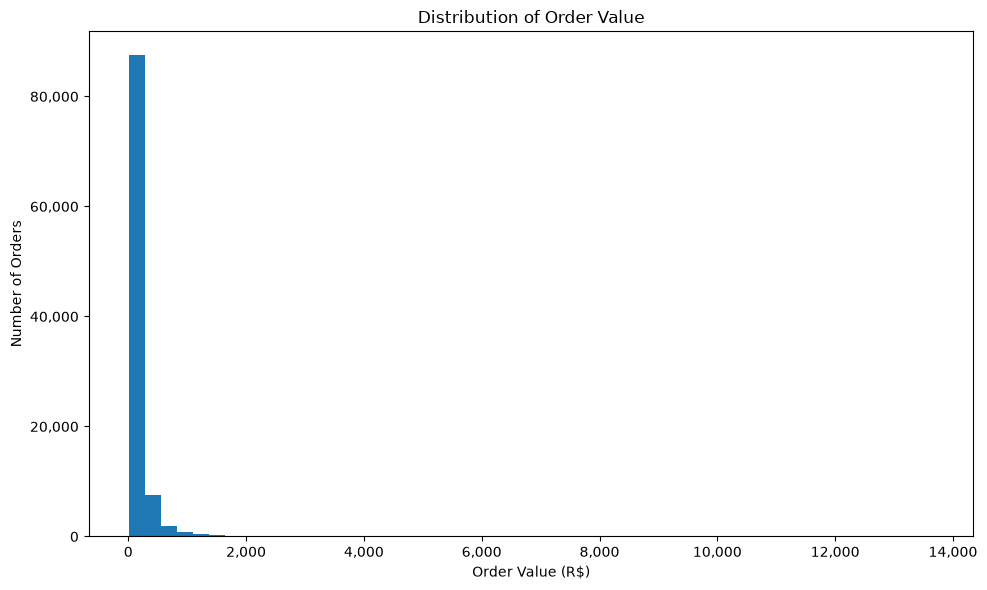

In [53]:
# ============================================================
# 9. ORDER VALUE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    df["order_value"],
    bins=50
)

plt.xlabel("Order Value (R$)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Order Value")

plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

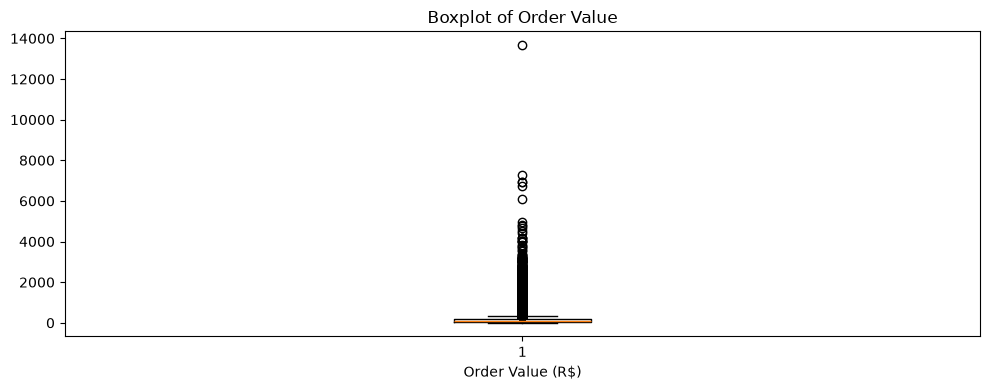

In [54]:
# ============================================================
# 10. ORDER VALUE BOXPLOT
# ============================================================

plt.figure(figsize=(10, 4))

plt.boxplot(
    df["order_value"],
    orientation = 'vertical'
)

plt.xlabel("Order Value (R$)")
plt.title("Boxplot of Order Value")

plt.tight_layout()
plt.show()


Original skewness: 9.227552388254525
Log-transformed skewness: 0.5468996690669904


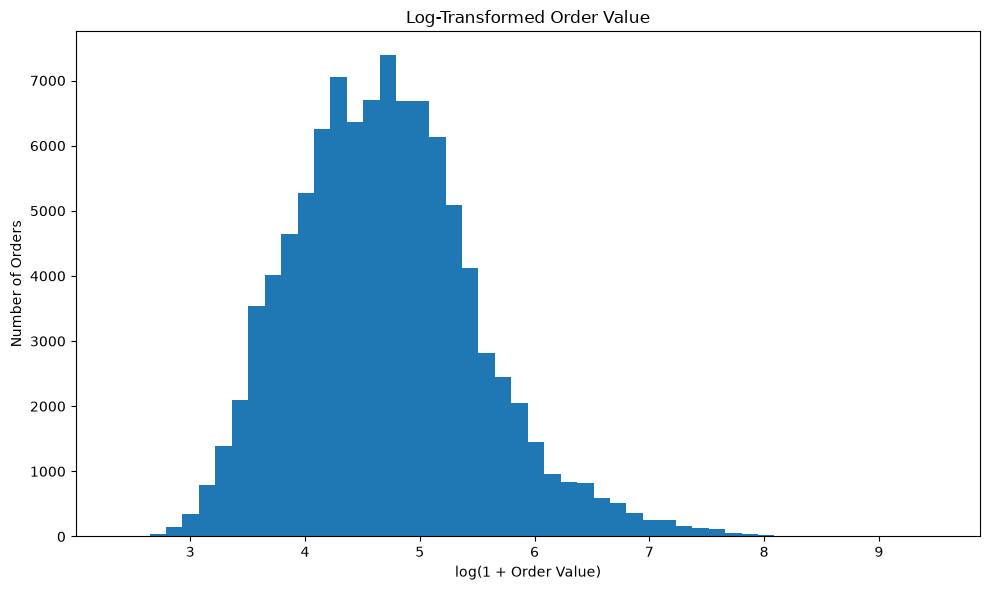

In [55]:
# ============================================================
# 11. LOG TRANSFORMATION
# ============================================================

# Order value is expected to be right-skewed.
# log1p reduces the influence of extreme values.

df["log_order_value"] = np.log1p(
    df["order_value"]
)

print("\nOriginal skewness:",
      df["order_value"].skew())

print("Log-transformed skewness:",
      df["log_order_value"].skew())


plt.figure(figsize=(10, 6))

plt.hist(
    df["log_order_value"],
    bins=50
)

plt.xlabel("log(1 + Order Value)")
plt.ylabel("Number of Orders")
plt.title("Log-Transformed Order Value")

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# 12. NUMERIC FEATURE CORRELATION
# ============================================================

print("\n" + "=" * 70)
print("CORRELATION WITH ORDER VALUE")
print("=" * 70)

numeric_columns = df.select_dtypes(
    include=np.number
).columns

correlations = (
    df[numeric_columns]
    .corr()["order_value"]
    .sort_values(
        ascending=False
    )
)

print(correlations)


CORRELATION WITH ORDER VALUE
order_value                  1.00
average_item_price           0.92
log_order_value              0.76
average_item_freight         0.46
average_product_weight_g     0.37
payment_installments         0.32
average_product_height_cm    0.25
number_of_items              0.19
average_product_width_cm     0.19
average_product_length_cm    0.17
number_of_products           0.08
number_of_sellers_x          0.05
number_of_sellers_y          0.05
number_of_seller_states      0.04
number_of_categories         0.03
purchase_hour                0.00
purchase_month               0.00
number_of_payment_records    0.00
purchase_year                0.00
purchase_dayofweek          -0.00
purchase_day                -0.01
Name: order_value, dtype: float64


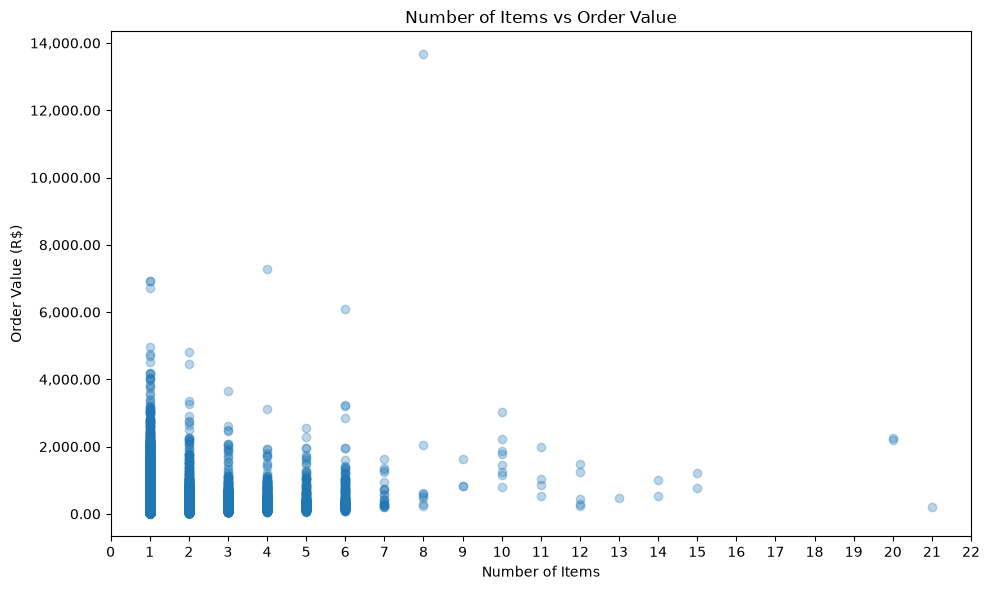

In [59]:
# ============================================================
# 13. NUMBER OF ITEMS VS ORDER VALUE
# ============================================================
from matplotlib.ticker import MultipleLocator, StrMethodFormatter

if "number_of_items" in df.columns:

    plt.figure(figsize=(10, 6))

    plt.scatter(
        df["number_of_items"],
        df["order_value"],
        alpha=0.3
    )

    plt.xlabel("Number of Items")
    plt.ylabel("Order Value (R$)")
    plt.title(
        "Number of Items vs Order Value"
    )
    
    # Use plt.gca() to target the active plot for the MultipleLocator
    plt.gca().xaxis.set_major_locator(MultipleLocator(1))
    
    # Optional: Keep formatting consistent with previous charts
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.2f}'))

    plt.tight_layout()
    plt.show()

In [60]:
# ============================================================
# 14. OUTLIER ANALYSIS
# ============================================================

Q1 = df["order_value"].quantile(0.25)
Q3 = df["order_value"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df["order_value"] < lower_bound)
    |
    (df["order_value"] > upper_bound)
)

print("\n" + "=" * 70)
print("OUTLIER ANALYSIS")
print("=" * 70)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print(
    "Number of outliers:",
    outlier_mask.sum()
)

print(
    "Percentage of observations:",
    round(
        outlier_mask.mean() * 100,
        2
    ),
    "%"
)


OUTLIER ANALYSIS
Q1: 61.98
Q3: 176.87
IQR: 114.89000000000001
Lower bound: -110.35500000000005
Upper bound: 349.20500000000004
Number of outliers: 7775
Percentage of observations: 7.88 %


In [61]:
# ============================================================
# 15. TRAIN / VAL / TEST SPLIT
# ============================================================

# Split BEFORE determining the classification threshold.
# This prevents information from the test set influencing
# the definition of a high-value order.

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("\n" + "=" * 70)
print("TRAIN / VAL / TEST SPLIT")
print("=" * 70)

print("Training observations:",
      len(train_df))

print("Validation observations:",
      len(val_df))

print("Testing observations:",
      len(test_df))


TRAIN / VAL / TEST SPLIT
Training observations: 69066
Validation observations: 14800
Testing observations: 14800


In [62]:
# ============================================================
# 16. CLASSIFICATION TARGET
# ============================================================

# The threshold is calculated ONLY from training data.

high_value_threshold = (
    train_df["order_value"]
    .quantile(0.80)
)

print("\n" + "=" * 70)
print("HIGH-VALUE ORDER THRESHOLD")
print("=" * 70)

print(
    "80th percentile threshold:",
    f"R$ {high_value_threshold:,.2f}"
)


# Create classification target

train_df["high_value_order"] = (
    train_df["order_value"]
    >= high_value_threshold
).astype(int)

test_df["high_value_order"] = (
    test_df["order_value"]
    >= high_value_threshold
).astype(int)


HIGH-VALUE ORDER THRESHOLD
80th percentile threshold: R$ 202.00


In [63]:
# ============================================================
# 17. CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

train_class_distribution = (
    train_df["high_value_order"]
    .value_counts()
    .sort_index()
)

train_class_percentage = (
    train_df["high_value_order"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

class_summary = pd.DataFrame({
    "count": train_class_distribution,
    "percentage": train_class_percentage
})

class_summary.index = [
    "Standard Order"
    if index == 0
    else "High-Value Order"
    for index in class_summary.index
]

print(class_summary)


CLASS DISTRIBUTION
                  count  percentage
Standard Order    55251       80.00
High-Value Order  13815       20.00


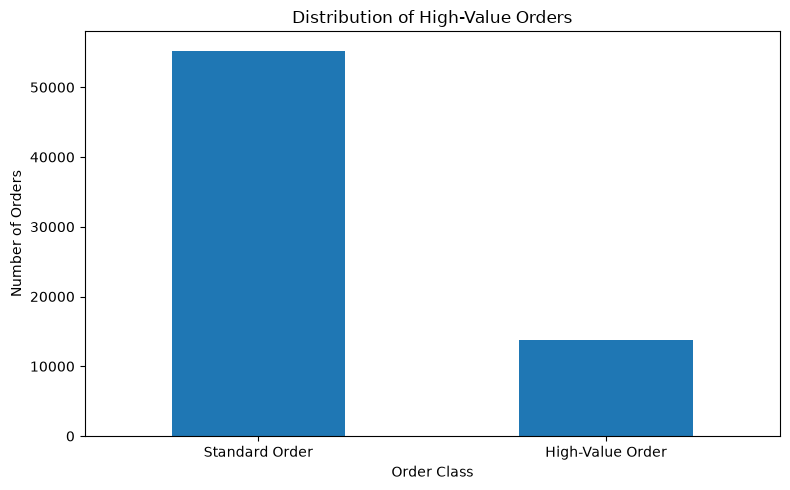

In [64]:
# ============================================================
# 18. CLASS DISTRIBUTION VISUALISATION
# ============================================================

plt.figure(figsize=(8, 5))

train_df[
    "high_value_order"
].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks(
    [0, 1],
    ["Standard Order", "High-Value Order"],
    rotation=0
)

plt.xlabel("Order Class")
plt.ylabel("Number of Orders")
plt.title(
    "Distribution of High-Value Orders"
)

plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# 19. ORDER VALUE BY CLASS
# ============================================================

standard_orders = train_df.loc[
    train_df["high_value_order"] == 0,
    "order_value"
]

high_value_orders = train_df.loc[
    train_df["high_value_order"] == 1,
    "order_value"
]

print("\n" + "=" * 70)
print("ORDER VALUE BY CLASS")
print("=" * 70)

print("\nStandard orders:")
print(standard_orders.describe())

print("\nHigh-value orders:")
print(high_value_orders.describe())


ORDER VALUE BY CLASS

Standard orders:
count   55251.00
mean       93.64
std        47.13
min         9.59
25%        54.60
50%        85.44
75%       128.39
max       201.99
Name: order_value, dtype: float64

High-value orders:
count   13815.00
mean      427.30
std       365.67
min       202.00
25%       236.91
50%       307.98
75%       448.96
max      7274.88
Name: order_value, dtype: float64


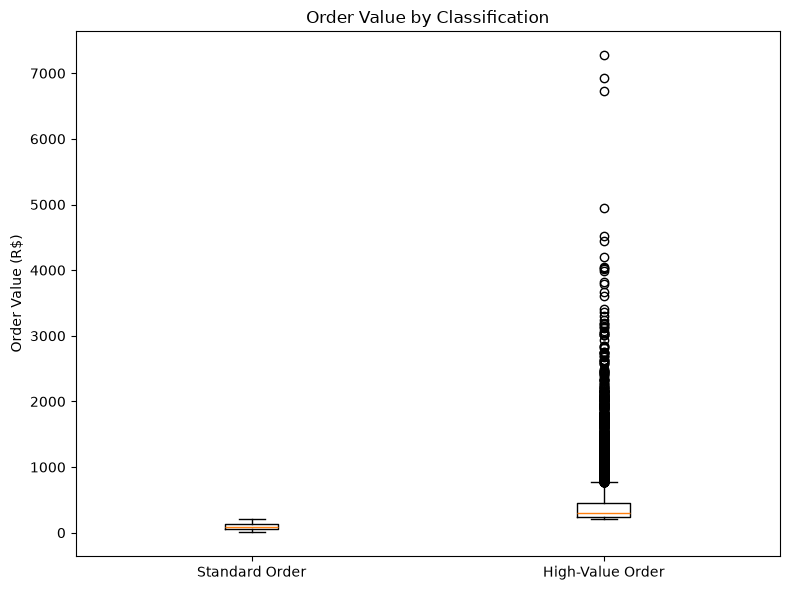

In [66]:
# ============================================================
# 20. CLASSIFICATION BOXPLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        standard_orders,
        high_value_orders
    ],
    tick_labels=[
        "Standard Order",
        "High-Value Order"
    ]
)

plt.ylabel("Order Value (R$)")
plt.title(
    "Order Value by Classification"
)

plt.tight_layout()
plt.show()


['order_id', 'customer_id', 'order_status', 'customer_city', 'customer_state', 'number_of_items', 'average_item_price', 'average_item_freight', 'number_of_sellers_x', 'number_of_products', 'order_value', 'average_product_weight_g', 'average_product_length_cm', 'average_product_height_cm', 'average_product_width_cm', 'number_of_categories', 'number_of_sellers_y', 'number_of_seller_states', 'primary_seller_state', 'number_of_payment_records', 'payment_installments', 'payment_type', 'purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_hour', 'log_order_value', 'high_value_order']


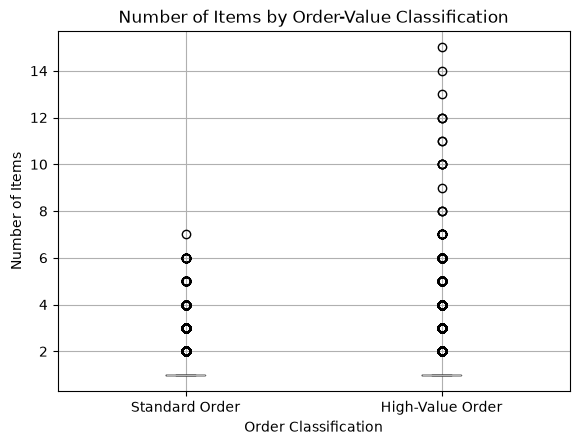

In [67]:
print(train_df.columns.tolist())

train_df.boxplot(
    column="number_of_items",
    by="high_value_order"
)

plt.xlabel("Order Classification")
plt.ylabel("Number of Items")
plt.title("Number of Items by Order-Value Classification")
plt.suptitle("")

plt.xticks(
    [1, 2],
    ["Standard Order", "High-Value Order"]
)

plt.show()

In [68]:
# ============================================================
# 21. OPTIONAL CATEGORY EDA
# ============================================================

if "product_category" in train_df.columns:

    category_summary = (
        train_df
        .groupby("product_category")
        .agg(
            mean_order_value=(
                "order_value",
                "mean"
            ),

            median_order_value=(
                "order_value",
                "median"
            ),

            number_of_orders=(
                "order_value",
                "count"
            ),

            high_value_rate=(
                "high_value_order",
                "mean"
            )
        )
        .sort_values(
            "mean_order_value",
            ascending=False
        )
    )

    category_summary[
        "high_value_rate"
    ] *= 100

    print("\n" + "=" * 70)
    print("ORDER VALUE BY PRODUCT CATEGORY")
    print("=" * 70)

    print(
        category_summary.head(20)
    )

In [69]:
# ============================================================
# 22. OPTIONAL STATE EDA
# ============================================================

if "customer_state" in train_df.columns:

    state_summary = (
        train_df
        .groupby("customer_state")
        .agg(
            mean_order_value=(
                "order_value",
                "mean"
            ),

            median_order_value=(
                "order_value",
                "median"
            ),

            number_of_orders=(
                "order_value",
                "count"
            ),

            high_value_rate=(
                "high_value_order",
                "mean"
            )
        )
        .sort_values(
            "mean_order_value",
            ascending=False
        )
    )

    state_summary[
        "high_value_rate"
    ] *= 100

    print("\n" + "=" * 70)
    print("ORDER VALUE BY CUSTOMER STATE")
    print("=" * 70)

    print(state_summary)


ORDER VALUE BY CUSTOMER STATE
                mean_order_value  median_order_value  number_of_orders  \
customer_state                                                           
PB                    259.899219             152.885               384   
RR                    256.246154             161.300                26   
AC                    252.145769             154.805                52   
RO                    245.431329             141.550               173   
AP                    235.468235             154.990                51   
PI                    228.552507             143.060               347   
PA                    224.431025             140.220               683   
RN                    218.852057             142.495               350   
AL                    218.028373             138.150               295   
MT                    212.805896             127.300               653   
SE                    208.618050             141.030               241   
CE     

In [69]:
# ============================================================
# 23. DEFINE MODELLING FEATURES
# ============================================================

print("\n" + "=" * 70)
print("MODELLING FEATURES")
print("=" * 70)

# Variables that should NOT be predictors.
#
# Reasons:
# - IDs: identifiers, not meaningful predictors
# - Target variables: direct leakage
# - Target components: directly construct order_value
# - Post-purchase variables: unavailable at prediction point

excluded_columns = [
    "order_id",
    "customer_id",

    # Regression target
    "order_value",

    # Classification target
    "high_value_order",

    # Target components
    "price",
    "freight_value",
    "total_price",
    "total_freight",

    # Derived target transformation
    "log_order_value",

    # Post-purchase / leakage variables
    "review_score",
    "review_comment_message",
    "order_delivered_customer_date",
    "order_delivered_carrier_date"
]


# Only remove columns that actually exist

excluded_columns = [
    column
    for column in excluded_columns
    if column in train_df.columns
]


feature_columns = [
    column
    for column in train_df.columns
    if column not in excluded_columns
]


print("\nExcluded columns:")
print(excluded_columns)

print("\nCandidate modelling features:")
print(feature_columns)


MODELLING FEATURES

Excluded columns:
['order_id', 'customer_id', 'order_value', 'high_value_order', 'log_order_value']

Candidate modelling features:
['order_status', 'customer_city', 'customer_state', 'number_of_items', 'average_item_price', 'average_item_freight', 'number_of_sellers_x', 'number_of_products', 'average_product_weight_g', 'average_product_length_cm', 'average_product_height_cm', 'average_product_width_cm', 'number_of_categories', 'number_of_sellers_y', 'number_of_seller_states', 'primary_seller_state', 'number_of_payment_records', 'payment_installments', 'payment_type', 'purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_hour']


In [70]:
# ============================================================
# 24. CREATE X AND y FOR REGRESSION
# ============================================================

X_train_reg = train_df[
    feature_columns
].copy()

X_test_reg = test_df[
    feature_columns
].copy()

y_train_reg = train_df[
    "order_value"
].copy()

y_test_reg = test_df[
    "order_value"
].copy()

In [71]:
# ============================================================
# 25. CREATE X AND y FOR CLASSIFICATION
# ============================================================

X_train_cls = train_df[
    feature_columns
].copy()

X_test_cls = test_df[
    feature_columns
].copy()

y_train_cls = train_df[
    "high_value_order"
].copy()

y_test_cls = test_df[
    "high_value_order"
].copy()

In [72]:
# ============================================================
# 26. CHECK FINAL DATA
# ============================================================

print("\n" + "=" * 70)
print("FINAL MODELLING DATA")
print("=" * 70)

print(
    "Regression X_train:",
    X_train_reg.shape
)

print(
    "Regression X_test:",
    X_test_reg.shape
)

print(
    "Classification X_train:",
    X_train_cls.shape
)

print(
    "Classification X_test:",
    X_test_cls.shape
)

print(
    "Regression target:",
    y_train_reg.shape
)

print(
    "Classification target:",
    y_train_cls.shape
)


FINAL MODELLING DATA
Regression X_train: (69066, 24)
Regression X_test: (14800, 24)
Classification X_train: (69066, 24)
Classification X_test: (14800, 24)
Regression target: (69066,)
Classification target: (69066,)


In [73]:
# ============================================================
# 27. FINAL CLASS BALANCE CHECK
# ============================================================

print("\nTraining classification target:")
print(
    y_train_cls.value_counts(
        normalize=True
    ) * 100
)

print("\nTesting classification target:")
print(
    y_test_cls.value_counts(
        normalize=True
    ) * 100
)


Training classification target:
high_value_order
0   80.00
1   20.00
Name: proportion, dtype: float64

Testing classification target:
high_value_order
0   79.73
1   20.27
Name: proportion, dtype: float64


In [74]:
# ============================================================
# 28. SAVE PREPROCESSED DATA
# ============================================================

train_df.to_csv(
    "olist_order_value_train.csv",
    index=False
)

test_df.to_csv(
    "olist_order_value_test.csv",
    index=False
)

print("\n" + "=" * 70)
print("PREPROCESSING COMPLETE")
print("=" * 70)

print(
    "Training data saved as: "
    "olist_order_value_train.csv"
)

print(
    "Testing data saved as: "
    "olist_order_value_test.csv"
)


PREPROCESSING COMPLETE
Training data saved as: olist_order_value_train.csv
Testing data saved as: olist_order_value_test.csv


In [75]:
from sklearn.dummy import DummyRegressor

baseline_reg = DummyRegressor(strategy="median")

baseline_reg.fit(X_train_reg, y_train_reg)

y_pred_baseline = baseline_reg.predict(X_test_reg)

In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_reg, y_pred_baseline)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_baseline))
r2 = r2_score(y_test_reg, y_pred_baseline)

print("Baseline MAE:", mae)
print("Baseline RMSE:", rmse)
print("Baseline R²:", r2)

Baseline MAE: 99.58365270270271
Baseline RMSE: 248.55583766008274
Baseline R²: -0.05460525797658522


In [77]:
baseline_reg = DummyRegressor(strategy="mean")

baseline_reg.fit(X_train_reg, y_train_reg)

y_pred_baseline = baseline_reg.predict(X_test_reg)

In [78]:
mae = mean_absolute_error(y_test_reg, y_pred_baseline)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_baseline))
r2 = r2_score(y_test_reg, y_pred_baseline)

print("Baseline MAE:", mae)
print("Baseline RMSE:", rmse)
print("Baseline R²:", r2)

Baseline MAE: 111.58292866521721
Baseline RMSE: 242.0398458057754
Baseline R²: -3.622564030592024e-05


In [79]:
from sklearn.dummy import DummyClassifier

baseline_clf = DummyClassifier(strategy="most_frequent")

baseline_clf.fit(X_train_cls, y_train_cls)

y_pred_baseline = baseline_clf.predict(X_test_cls)

In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test_cls, y_pred_baseline))
print("Precision:", precision_score(y_test_cls, y_pred_baseline, zero_division=0))
print("Recall:", recall_score(y_test_cls, y_pred_baseline, zero_division=0))
print("F1:", f1_score(y_test_cls, y_pred_baseline, zero_division=0))

Accuracy: 0.7972972972972973
Precision: 0.0
Recall: 0.0
F1: 0.0


In [ ]:
# TODO